# Ошибки, пропуски и воспроизводимость

Разберём типичные ошибки данных и проверим, что исходная таблица не меняется. Недостаток наблюдений считается после очистки: меньше пяти в любой группе — ошибка, от пяти до девятнадцати — предупреждение.

In [1]:
import sys
from pathlib import Path

# Примеры работают из корня проекта и из папки examples.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте ноутбук из папки проекта RainView.")
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rainview import format_summary, raincloudplot

%matplotlib inline

from rainview import RainViewError

In [2]:
data = pd.read_csv(ROOT / "data" / "education.csv")
original = data.copy(deep=True)


def explain(call):
    try:
        call()
    except RainViewError as error:
        print(type(error).__name__ + ":", error)


explain(lambda: raincloudplot(data, "missing", "method"))

ColumnNotFoundError: Столбец "missing" не найден в DataFrame.


In [3]:
bad = data.copy()
bad["score"] = bad["score"].astype(str)
explain(lambda: raincloudplot(bad, "score", "method"))

NonNumericColumnError: Для построения графика требуется числовой столбец: "score". Строки, логические и комплексные значения не поддерживаются.


In [4]:
empty = data.copy()
empty.loc[empty["method"] == "Интерактивный", "score"] = np.nan
explain(lambda: raincloudplot(empty, "score", "method"))

EmptyGroupError: После удаления пропусков в группе "Интерактивный" не осталось наблюдений.


In [5]:
tiny = data.groupby("method", sort=False).head(4)
explain(lambda: raincloudplot(tiny, "score", "method"))

InsufficientDataError: Минимальное количество наблюдений в группе: 5. В группе "Традиционный": 4.


## Постоянные группы

Когда все значения равны, гладкую плотность оценить нельзя. RainView выдаёт предупреждение и рисует линию на наблюдаемом значении, сохраняя реальные точки и boxplot.

/tmp/ipykernel_24979/2160673587.py:2: ConstantGroupWarning: В группе "A" плотность не определена из-за отсутствия разброса или численной вырожденности. Вместо half-violin показана линия.
  fig_constant, _, constant_summary = raincloudplot(
/tmp/ipykernel_24979/2160673587.py:2: ConstantGroupWarning: В группе "B" плотность не определена из-за отсутствия разброса или численной вырожденности. Вместо half-violin показана линия.
  fig_constant, _, constant_summary = raincloudplot(


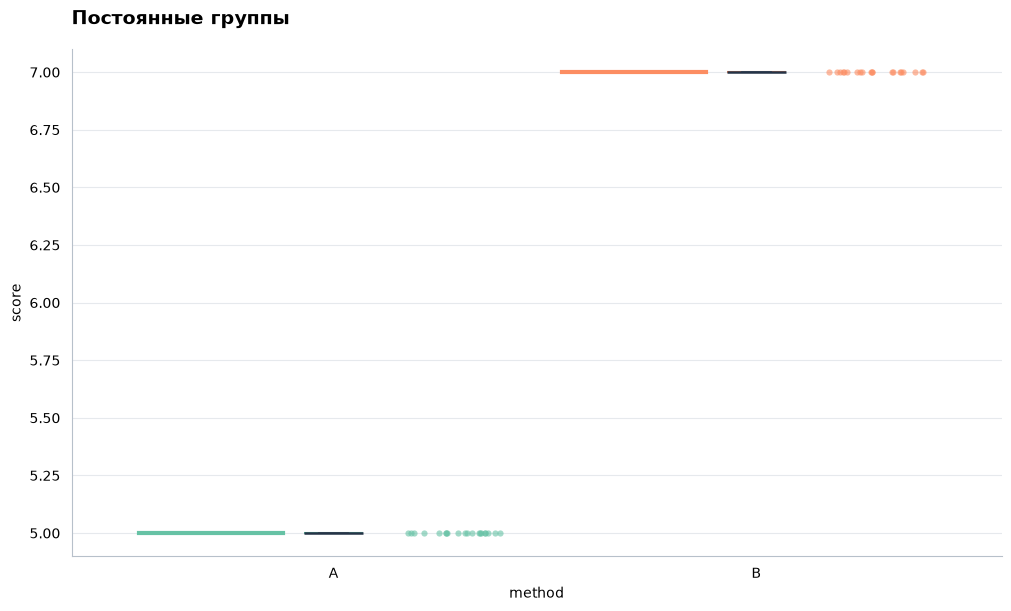

Всего строк: 40; использовано: 40; исключено: 0.
Из них без метки группы: 0.
A: n=20, среднее=5, медиана=5, std=0, min=5, max=5, исключено в группе=0.
B: n=20, среднее=7, медиана=7, std=0, min=7, max=7, исключено в группе=0.


In [6]:
constant = pd.DataFrame({"method": ["A"] * 20 + ["B"] * 20, "score": [5.0] * 20 + [7.0] * 20})
fig_constant, _, constant_summary = raincloudplot(
    constant, "score", "method", title="Постоянные группы"
)
plt.show()
print(format_summary(constant_summary))

## Проверка повторяемого jitter

Фиксированный random_state даёт одинаковые координаты точек. Значения измерений не меняются; смещение применяется только вдоль оси групп.

In [7]:
from matplotlib.collections import PathCollection

fig1, ax1, summary1 = raincloudplot(data, "score", "method", random_state=42)
fig2, ax2, summary2 = raincloudplot(data, "score", "method", random_state=42)
points1 = [a for a in ax1.collections if isinstance(a, PathCollection)]
points2 = [a for a in ax2.collections if isinstance(a, PathCollection)]
for left, right in zip(points1, points2, strict=True):
    np.testing.assert_array_equal(left.get_offsets(), right.get_offsets())
pd.testing.assert_frame_equal(data, original)
assert summary1 == summary2
plt.close(fig1)
plt.close(fig2)
print("Проверено: jitter и сводка повторяются, исходная таблица не меняется.")

Проверено: jitter и сводка повторяются, исходная таблица не меняется.


/tmp/ipykernel_24979/2081329512.py:3: MissingDataWarning: Исключено строк с пропусками: 3 из 150. Подробности находятся в summary.
  fig1, ax1, summary1 = raincloudplot(data, "score", "method", random_state=42)
/tmp/ipykernel_24979/2081329512.py:4: MissingDataWarning: Исключено строк с пропусками: 3 из 150. Подробности находятся в summary.
  fig2, ax2, summary2 = raincloudplot(data, "score", "method", random_state=42)
